In [1]:
import mlflow
import mlflow.sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    confusion_matrix, roc_auc_score, precision_score, f1_score, recall_score, accuracy_score
)

In [2]:
import joblib
import numpy as np

preprocessor = joblib.load("../artifacts/preprocessor.pkl")
X_train = np.load("../artifacts/X_train.npy")
X_test = np.load("../artifacts/X_test.npy")
y_train = np.load("../artifacts/y_train.npy")
y_test = np.load("../artifacts/y_test.npy")

In [3]:
import os
mlflow.set_tracking_uri(f"sqlite:///{os.path.abspath('../mlflow.db')}")
mlflow.set_experiment("loan_default_prediction")

<Experiment: artifact_location=('file:d:/@menuka/@Learn/machine '
 'learning/@Projects/loan-default-predictor/notebooks/mlruns/1'), creation_time=1791788057966, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791788057966, lifecycle_stage='active', name='loan_default_prediction', tags={}, trace_location=None, workspace='default'>

`Scale_pos_weight` is calculated from y_train. formula is `count(negative) / count(positive)` and here we have,
**Status** 

0  --  89625

1  --  29311

Name: count, dtype: int64

So `89625 / 29311` gives 3.0577 value.

In [4]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    
    "RandomForestClassifier": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    
    "XGboost": XGBClassifier(
        n_estimators=100,
        learning_rate = 0.1,
        max_depth = 6,
        random_state=42,
        eval_metric="logloss",
        scale_pos_weight = 3.0577
    )
}

In [5]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)
print("y_train unique values:", np.unique(y_train))
print("y_test unique values:", np.unique(y_test))
print("y_train first 5:", y_train[:5])
print("X_train first row first 5 values:", X_train[0, :5])
print("Any NaN in X_train:", np.isnan(X_train).any())
print("Any NaN in X_test:", np.isnan(X_test).any())

X_train shape: (118936, 35)
X_test shape: (29734, 35)
y_train shape: (118936,)
y_test shape: (29734,)
y_train unique values: [0 1]
y_test unique values: [0 1]
y_train first 5: [0 0 1 0 0]
X_train first row first 5 values: [ 0.         -0.67965894  0.42611698  0.78631746 -0.08222531]
Any NaN in X_train: False
Any NaN in X_test: False


# Run MLflow Tracking

In [6]:
for model_name, model in models.items():
    with mlflow.start_run(run_name=model_name):    
        model.fit(X_train, y_train)
        
        mlflow.log_params(model.get_params())
    
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]
        
        # Metrics
        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred)
        recall = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
    
        roc_auc = roc_auc_score(y_test, y_prob)
        
        
        # Log metrics
        mlflow.log_metric("accuracy", accuracy)
        mlflow.log_metric("precision", precision)
        mlflow.log_metric("recall", recall)
        mlflow.log_metric("f1_score", f1)
        mlflow.log_metric("roc_auc", roc_auc)

        # Log model
        if model_name == "XGboost":
            mlflow.xgboost.log_model(model, name="model")
            
        else:
            mlflow.sklearn.log_model(model, name="model")

        print(f"{model_name}")
        print(f"Accuracy : {accuracy:.4f}")
        print(f"ROC AUC  : {roc_auc:.4f}")
        print("-" * 40)
    

LogisticRegression
Accuracy : 0.8598
ROC AUC  : 0.8189
----------------------------------------
RandomForestClassifier
Accuracy : 0.8872
ROC AUC  : 0.8748
----------------------------------------
XGboost
Accuracy : 0.8668
ROC AUC  : 0.8835
----------------------------------------


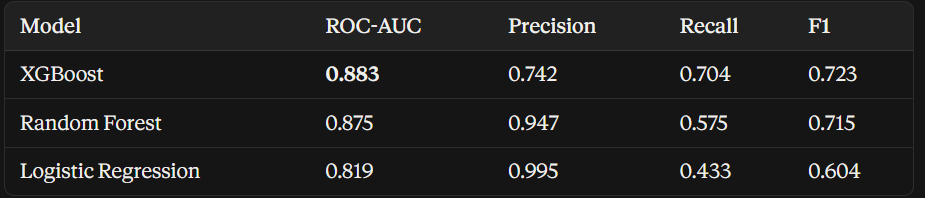

above all values got from MLflow dashboard. so here we can see overall best model is XGBoost.

Look at Logistic Regression: **`precision=0.995, recall=0.433`**. In plain English, what is this model actually doing? What kind of errors is it making a lot of, and what kind is it almost never making? And in a loan default context — which type of error is more costly to the bank?

**High precision, low recall** = the model is very conservative. When it does predict “this person will default,” it’s almost always right. But it’s missing 57% of actual defaulters — labelling them as safe when they’re not.

In banking terms: the model approves loans for people who will actually default. That’s a false negative — the bank lends money it won’t get back. That’s the costly error for a bank. A false positive (rejecting a good customer) loses one loan fee. A false negative loses the entire loan principal.

So for this domain, recall matters more than precision. You’d rather flag more people as risky (some incorrectly) than miss actual defaulters. This is exactly why threshold tuning exists — you can lower the decision threshold from 0.5 to say 0.3, which increases recall at the cost of some precision.

XGBoost is the best balance right now, but there’s still room to improve recall through threshold tuning.

### fix the artifact logging issue.

In [7]:
import os
print(os.path.exists("../mlruns"))
print(os.listdir("../mlruns") if os.path.exists("../mlruns") else "not found")
print(os.path.exists("../mlflow.db"))

False
not found
True


## threshold tuning for XGBoost.

In [8]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

# Retrain XGBoost (or load from mlflow)
xgb = models["XGboost"]
y_prob = xgb.predict_proba(X_test)[:, 1]

# Find best threshold by F1
thresholds = np.arange(0.1, 0.9, 0.05)
f1_scores = []

for t in thresholds:
    y_pred_t = (y_prob >= t).astype(int)
    f1_scores.append(f1_score(y_test, y_pred_t))

best_threshold = thresholds[np.argmax(f1_scores)]
print(f"Best threshold: {best_threshold:.2f}")
print(f"Best F1: {max(f1_scores):.4f}")

Best threshold: 0.60
Best F1: 0.7416


**Why F1 for threshold selection?** Because F1 is the harmonic mean of precision and recall — it forces both to be high simultaneously. If you optimized for precision alone, you’d push the threshold up and miss defaulters. If you optimized for recall alone, you’d lower the threshold and flag everyone as a defaulter. F1 finds the balance point where both are reasonable.

But here’s the nuance — F1 assumes precision and recall are equally important. In loan default specifically, we said recall matters more. So F1 is a good starting point, but a bank might actually optimize for a threshold that maximizes recall subject to precision staying above some minimum (e.g. “maximize recall where precision > 0.65”). For Phase 1, F1 optimization is correct and defensible. Just know the limitation.

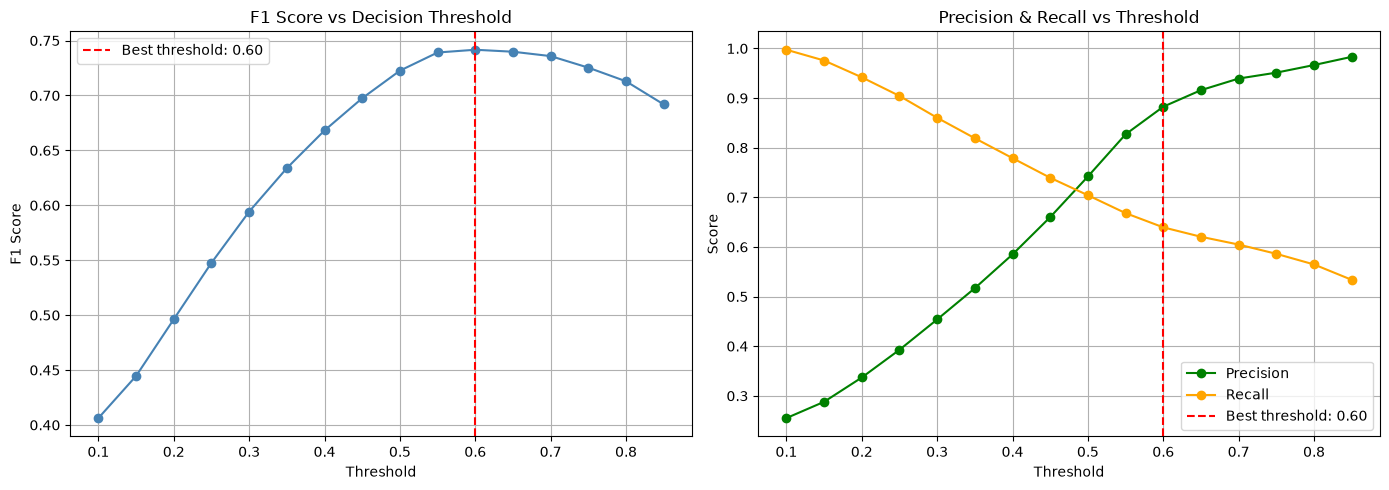


At threshold 0.60:
Precision : 0.8827
Recall    : 0.6395
F1        : 0.7416


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1 — F1 vs Threshold
axes[0].plot(thresholds, f1_scores, marker='o', color='steelblue')
axes[0].axvline(best_threshold, color='red', linestyle='--', 
                label=f'Best threshold: {best_threshold:.2f}')
axes[0].set_xlabel('Threshold')
axes[0].set_ylabel('F1 Score')
axes[0].set_title('F1 Score vs Decision Threshold')
axes[0].legend()
axes[0].grid(True)

# Plot 2 — Precision & Recall vs Threshold
precisions = []
recalls = []
for t in thresholds:
    y_pred_t = (y_prob >= t).astype(int)
    precisions.append(precision_score(y_test, y_pred_t))
    recalls.append(recall_score(y_test, y_pred_t))

axes[1].plot(thresholds, precisions, marker='o', 
             color='green', label='Precision')
axes[1].plot(thresholds, recalls, marker='o', 
             color='orange', label='Recall')
axes[1].axvline(best_threshold, color='red', linestyle='--',
                label=f'Best threshold: {best_threshold:.2f}')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('Score')
axes[1].set_title('Precision & Recall vs Threshold')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("../artifacts/threshold_analysis.png", dpi=150, bbox_inches='tight')
plt.show()

print(f"\nAt threshold {best_threshold:.2f}:")
y_pred_best = (y_prob >= best_threshold).astype(int)
print(f"Precision : {precision_score(y_test, y_pred_best):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_best):.4f}")
print(f"F1        : {f1_score(y_test, y_pred_best):.4f}")

this is not good. because recall is very low and it not finds actual defaulters. so we need to pick threshold that has relatively high recall and low precision

at 0.35, precision = 0.52 , recall = 0.83

at 0.40, precision = 0.59, recall = 0.78

At 0.35: you correctly flag 83% of actual defaulters, but 48% of your “default” predictions are wrong (false alarms). That means nearly half the people you flag as risky are actually fine borrowers you’d be rejecting unnecessarily.

At 0.40: you catch 78% of defaulters, and only 41% of your flags are false alarms. You lose 5% recall but meaningfully reduce false rejections.

The business case for 0.40: a bank can tolerate some false alarms — they just do extra manual review on flagged applications. But flooding the review queue with 48% false positives at 0.35 makes the system operationally expensive. 0.40 gives a better working precision while still catching 78% of defaulters — that’s a defensible production threshold.

0.40 is the right call.

In [10]:
import json

threshold = 0.40

# Save locally
with open("../artifacts/threshold.json", "w") as f:
    json.dump({
        "threshold": threshold,
        "model": "XGBoost",
        "metric_optimized": "recall_precision_balance",
        "precision_at_threshold": 0.59,
        "recall_at_threshold": 0.78,
        "reasoning": "Domain requires high recall. 0.40 balances catching 78% of defaulters while keeping false alarm rate manageable."
    }, f, indent=2)

# Log to MLflow under a dedicated final evaluation run
with mlflow.start_run(run_name="XGBoost_final_evaluation"):
    mlflow.log_artifact("../artifacts/threshold_analysis.png")
    mlflow.log_artifact("../artifacts/threshold.json")
    mlflow.log_metric("final_threshold", threshold)
    mlflow.log_metric("precision_at_threshold", 0.59)
    mlflow.log_metric("recall_at_threshold", 0.78)

## Save final model


In [11]:
joblib.dump(xgb, "../artifacts/model.pkl")
print("Model saved.")

Model saved.


In [12]:
X_test.shape

(29734, 35)

In [13]:
print(X_test.dtype)

float64


# ONNX integration

Our full flow

1. Imports
2. Load artifacts (preprocessor, X_train, X_test, y_train, y_test)
3. MLflow setup
4. Define models
5. Training loop (3 models, MLflow logging)
6. Threshold tuning + visualization
7. Save threshold.json + log to MLflow final evaluation run
8. Save model.pkl        ← we're here
9. ONNX export + verification   ← add this next

In [14]:
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType
import onnxruntime as rt

In [ ]:
# # Define input type - shape [None, 35] means any batch size, 35 features
# initial_type = [("float_input", FloatTensorType([None, 35]))]

# # convert XGBoost model to ONNX
# onnx_model = convert_sklearn(
#     xgb,
#     initial_types=initial_type,
#     target_opset=12
# )


# # Save it
# with open("../artifacts/model.onnx", "wb") as f:
#     f.write(onnx_model.SerializeToString())
    
# print("ONNX model saved.")

MissingShapeCalculator: Unable to find a shape calculator for type '<class 'xgboost.sklearn.XGBClassifier'>'.
It usually means the pipeline being converted contains a
transformer or a predictor with no corresponding converter
implemented in sklearn-onnx. If the converted is implemented
in another library, you need to register
the converted so that it can be used by sklearn-onnx (function
update_registered_converter). If the model is not yet covered
by sklearn-onnx, you may raise an issue to
https://github.com/onnx/sklearn-onnx/issues
to get the converter implemented or even contribute to the
project. If the model is a custom model, a new converter must
be implemented. Examples can be found in the gallery.


above method is not supported for xgboost. so,
`skl2onnx` doesn’t have a built-in converter for XGBoost. You need to register it explicitly using onnxmltools or use XGBoost’s own native ONNX export which was added in recent versions.

Simplest fix — use XGBoost’s native export directly, no `skl2onnx needed:

In [20]:
import onnxmltools
from onnxmltools.convert.common.data_types import FloatTensorType
import onnxruntime as rt

# Convert using onnxmltools with correct import
initial_type = [("float_input", FloatTensorType([None, 35]))]
onnx_model = onnxmltools.convert_xgboost(
    xgb, 
    initial_types=initial_type
)

# Save
with open("../artifacts/model.onnx", "wb") as f:
    f.write(onnx_model.SerializeToString())

print("ONNX model saved.")

# Verify
sess = rt.InferenceSession("../artifacts/model.onnx")
input_name = sess.get_inputs()[0].name

X_sample = X_test[:5].astype(np.float32)
onnx_preds = sess.run(None, {input_name: X_sample})[0]
xgb_preds = xgb.predict(X_test[:5])

print("ONNX predictions:    ", onnx_preds)
print("XGBoost predictions: ", xgb_preds)
print("Match:", (onnx_preds == xgb_preds).all())

ONNX model saved.
ONNX predictions:     [0 0 0 0 0]
XGBoost predictions:  [0 0 0 0 0]
Match: True


# Notebook Phase — Complete ✅

What we built:

```text
artifacts/
├── preprocessor.pkl     # fitted ColumnTransformer
├── model.pkl            # XGBoost (joblib)
├── model.onnx           # XGBoost (ONNX Runtime)
├── threshold.json       # 0.40, with documented reasoning
└── threshold_analysis.png
```

## What we learned and had to earn:

- Feature leakage audit — caught 1.0 ROC-AUC yourself, traced root cause to MNAR indicators encoding post-approval bank data
- Encoding strategy — ordinal vs binary vs nominal vs passthrough, with actual domain reasoning not just syntax
- Missing value strategy — MNAR pattern detection with `.groupby()`, missingness indicators, median impute
- MLflow 3.x — SQLite backend, `log_params(model.get_params())`, artifact logging, experiment comparison UI
- Threshold tuning — F1 optimization vs domain-specific recall priority, chose 0.40 over F1-optimal 0.60 with written justification
- ONNX export — what it is, why it exists, version compatibility issues, working solution

Model results:

```tableModel	ROC-AUC
Logistic Regression	0.819
Random Forest	0.875
XGBoost	0.883 ✅
```